# Chapter 2: The experiment design, in numbers

This notebook is the analysis behind the [experiment design doc](../docs/company_documents/ch2_experiment_design_doc.md). At a company, the doc is what stakeholders read and sign; the notebook is where the data scientist works out the numbers in it.

**Read first:** the [request](../docs/company_documents/ch1a_request.md), the [kickoff notes](../docs/company_documents/ch1b_kickoff_notes.md) and the [experiment design doc](../docs/company_documents/ch2_experiment_design_doc.md), or chapters 1–2 of the [case study](../CASE_STUDY.md).

**What this notebook answers:**

1. What lift does a campaign need to pay for itself? (the break-even)
2. What lift can a 64,000-customer test detect? (the minimum detectable effect)
3. How likely is the test to detect the lift Marketing expects? (power)
4. How should the 64,000 customers be split?

It never reads the outcome columns (`visit`, `conversion`, `spend`). Everything here is done before launch.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from expt.power import (
    mde_mean,
    mde_proportion,
    power_proportions,
    sample_size_proportions,
    zero_inflated_sd,
)

## 1. Inputs from the kickoff

Every number here comes from the [kickoff notes](../docs/company_documents/ch1b_kickoff_notes.md). In a real project you would get them from Finance, the order system and the e-mail platform, and keep the source next to each one.

In [2]:
# Economics (Finance, order system, e-mail platform)
ORDER_MEAN = 100.0        # average order value, $
ORDER_SD = 90.0           # SD of order value, $
GROSS_MARGIN = 0.40
SEND_COST = 0.01          # $ per email
CREATIVE_COST = 8_000     # $ per campaign
ACTIVE_FILE = 640_000     # customers who bought in the last 12 months

# Behaviour in a normal fortnight without email (Operations)
BASE_VISIT = 0.10
BASE_PURCHASE = 0.005

# Marketing's expectation
EXPECTED_LIFT = 0.30      # +30% purchases

# Design constraints and statistical settings
TEST_SIZE = 64_000
N_CONFIRMATORY = 2        # men's vs holdout, women's vs holdout
ALPHA = 0.05 / N_CONFIRMATORY
POWER = 0.80

## 2. The break-even lift

At full rollout, each email costs the sending fee plus its share of the creative cost. An email pays for itself when the *extra* revenue it causes, times the margin, covers that cost.

In [3]:
cost_per_email = SEND_COST + CREATIVE_COST / ACTIVE_FILE
breakeven_revenue = cost_per_email / GROSS_MARGIN          # incremental revenue per email
breakeven_purchase_lift = breakeven_revenue / ORDER_MEAN   # extra purchases per customer
breakeven_relative = breakeven_purchase_lift / BASE_PURCHASE

print(f"Cost per email:                         ${cost_per_email:.4f}")
print(f"Break-even incremental revenue / email: ${breakeven_revenue:.3f}")
print(f"Break-even lift in purchase rate:       +{breakeven_purchase_lift:.3%} points "
      f"({breakeven_relative:+.0%} relative)")

Cost per email:                         $0.0225
Break-even incremental revenue / email: $0.056
Break-even lift in purchase rate:       +0.056% points (+11% relative)


**About 11%.** That is the smallest effect worth having. Anything above it makes money at scale; anything below it doesn't cover the creative cost.

## 3. What can the test detect?

With equal thirds, each group has 21,333 customers. The **minimum detectable effect (MDE)** is the smallest true lift the test detects 80% of the time.

Revenue per customer is zero for about 99.5% of customers, so its standard deviation comes from the zero-inflated formula $\text{Var} = p(\sigma^2 + \mu^2) - (p\mu)^2$, with $p$ the purchase rate and $\mu, \sigma$ the order value's mean and SD.

In [4]:
n_group = TEST_SIZE // 3
spend_mean = BASE_PURCHASE * ORDER_MEAN
spend_sd = zero_inflated_sd(BASE_PURCHASE, ORDER_MEAN, ORDER_SD)

mde = pd.DataFrame(
    {
        "baseline": [BASE_VISIT, BASE_PURCHASE, spend_mean],
        "MDE (absolute)": [
            mde_proportion(BASE_VISIT, n_group, n_group, ALPHA, POWER),
            mde_proportion(BASE_PURCHASE, n_group, n_group, ALPHA, POWER),
            mde_mean(spend_sd, n_group, n_group, ALPHA, POWER),
        ],
    },
    index=["Visit rate", "Purchase rate", "Revenue per customer ($)"],
)
mde["MDE (relative)"] = mde["MDE (absolute)"] / mde["baseline"]
print(f"{n_group:,} customers per group; revenue per customer: mean ${spend_mean:.2f}, SD ${spend_sd:.2f}")
mde.style.format({"baseline": "{:.4f}", "MDE (absolute)": "{:.4f}", "MDE (relative)": "{:+.0%}"})

21,333 customers per group; revenue per customer: mean $0.50, SD $9.50


,baseline,MDE (absolute),MDE (relative)
Visit rate,0.1000,0.0091,+9%
Purchase rate,0.0050,0.0023,+47%
Revenue per customer ($),0.5000,0.2836,+57%


## 4. The gap between what matters and what we can see

Break-even is about +11%, Marketing expects +30%, and the test reliably detects only about +47%. How likely is the test to detect each, and how big would it need to be?

In [5]:
mde_purchase_rel = mde.loc["Purchase rate", "MDE (relative)"]
rows = []
for label, lift in [
    ("Break-even", breakeven_relative),
    ("Marketing's expectation", EXPECTED_LIFT),
    ("This test's MDE", mde_purchase_rel),
]:
    p1 = BASE_PURCHASE * (1 + lift)
    rows.append({
        "scenario": label,
        "lift in purchases": lift,
        "chance this test detects it": power_proportions(BASE_PURCHASE, p1, n_group, n_group, ALPHA),
        "customers needed per group (80%)": sample_size_proportions(BASE_PURCHASE, p1, ALPHA, POWER)[0],
    })
gap = pd.DataFrame(rows).set_index("scenario")
gap.style.format({
    "lift in purchases": "{:+.0%}",
    "chance this test detects it": "{:.0%}",
    "customers needed per group (80%)": "{:,.0f}",
})

,lift in purchases,chance this test detects it,customers needed per group (80%)
scenario,,,
Break-even,+11%,7%,"315,627"
Marketing's expectation,+30%,42%,"48,301"
This test's MDE,+47%,80%,"21,334"


In [6]:
visit_power = power_proportions(BASE_VISIT, BASE_VISIT * 1.10, n_group, n_group, ALPHA)
print(f"For comparison, chance of detecting a +10% lift in visits: {visit_power:.0%}")

For comparison, chance of detecting a +10% lift in visits: 87%


Two uncomfortable facts, both written into the design doc:

- **Even the whole active file could not reliably detect the break-even lift.** It would need over 300,000 customers per group, almost 950,000 in total. Small effects that matter at scale are often invisible to a single test.
- **At Marketing's expected +30%, the test is closer to a coin flip than a sure thing.** That is why the decision rules define "not significant" as *inconclusive*, not *no effect*.

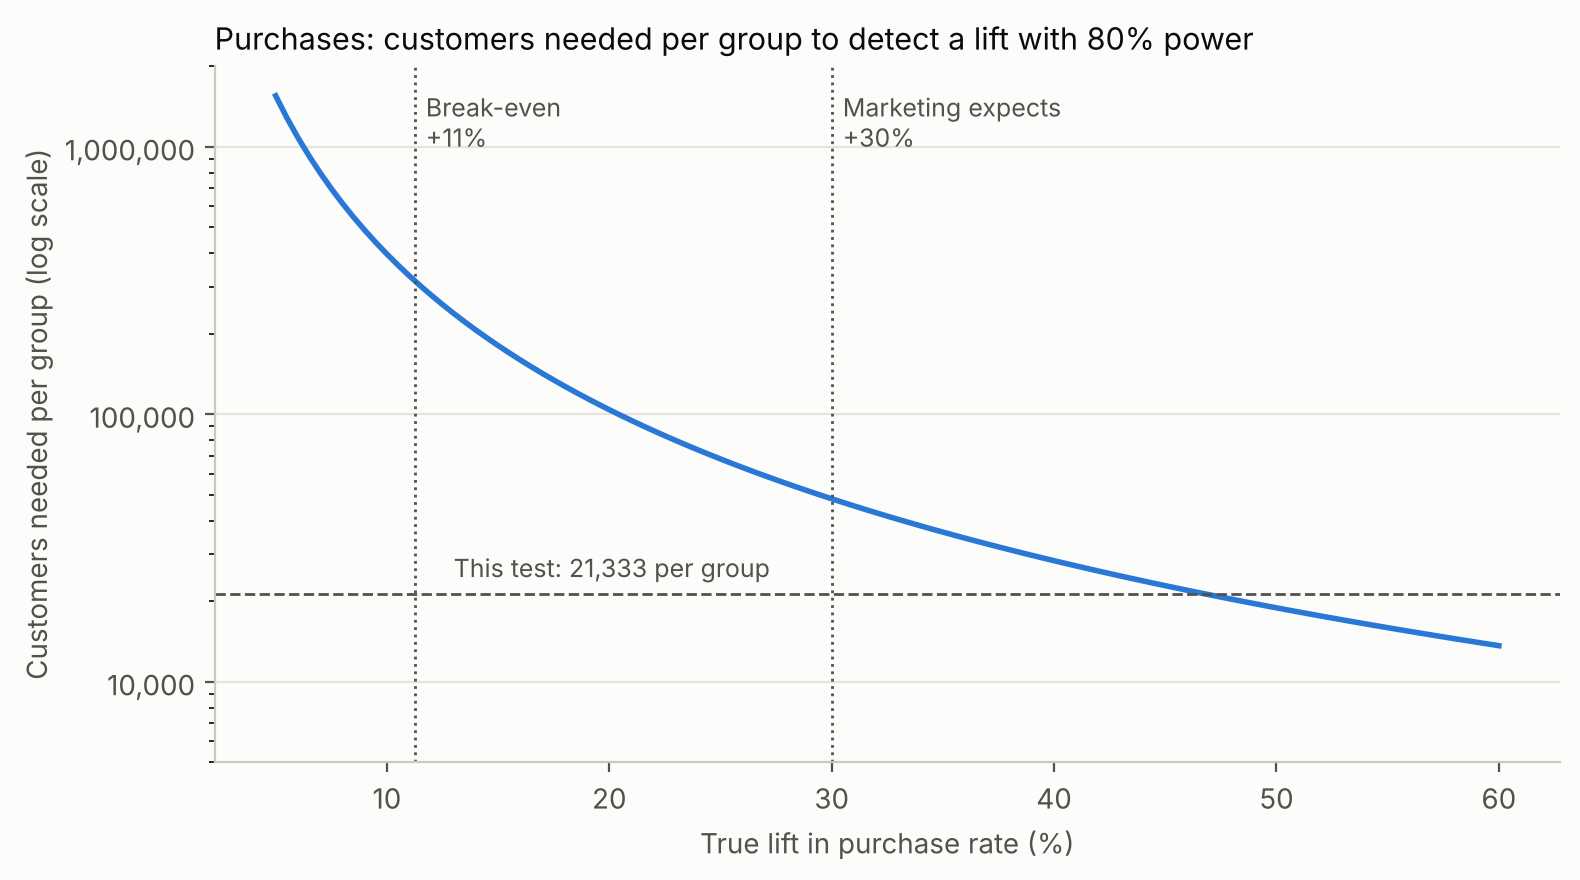

In [7]:
# figure: design_power
lifts = np.linspace(0.05, 0.60, 111)
needed = [sample_size_proportions(BASE_PURCHASE, BASE_PURCHASE * (1 + l), ALPHA, POWER)[0] for l in lifts]

INK, INK_2, SURFACE, GRID = "#0b0b0b", "#52514e", "#fcfcfb", "#e4e3df"
SERIES = "#2a78d6"

fig, ax = plt.subplots(figsize=(8, 4.5), facecolor=SURFACE)
ax.set_facecolor(SURFACE)
ax.plot(lifts * 100, needed, color=SERIES, linewidth=2)

ax.axhline(n_group, color=INK_2, linewidth=1, linestyle="--")
ax.annotate(f"This test: {n_group:,} per group", xy=(13, n_group), xytext=(0, 6),
            textcoords="offset points", ha="left", color=INK_2, fontsize=9)

for label, lift in [("Break-even\n+11%", breakeven_relative), ("Marketing expects\n+30%", EXPECTED_LIFT)]:
    ax.axvline(lift * 100, color=INK_2, linewidth=1, linestyle=":")
    ax.annotate(label, xy=(lift * 100, 1.6e6), xytext=(4, 0), textcoords="offset points",
                va="top", color=INK_2, fontsize=9)

ax.set_yscale("log")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.set_ylim(5_000, 2e6)
ax.set_xlabel("True lift in purchase rate (%)", color=INK_2)
ax.set_ylabel("Customers needed per group (log scale)", color=INK_2)
ax.set_title("Purchases: customers needed per group to detect a lift with 80% power",
             loc="left", color=INK, fontsize=11)
ax.grid(axis="y", color=GRID, linewidth=0.8)
ax.tick_params(colors=INK_2)
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)
for side in ["left", "bottom"]:
    ax.spines[side].set_color("#c9c8c3")
plt.tight_layout()
plt.show()

## 5. How to split the 64,000

A smaller holdout means more customers get the email during the test, which is what Marketing would naturally prefer. The cost is detection power. The benefit is the margin from emailing those extra customers, *if* the email works as hoped.

In [8]:
rows = []
for share in [0.10, 0.20, 1 / 3]:
    n_holdout = round(share * TEST_SIZE)
    n_email = round((1 - share) / 2 * TEST_SIZE)
    rel_mde = mde_proportion(BASE_PURCHASE, n_holdout, n_email, ALPHA, POWER) / BASE_PURCHASE
    rows.append({
        "holdout share": share,
        "holdout": n_holdout,
        "each email group": n_email,
        "smallest lift detected": rel_mde,
        "chance to detect +30%": power_proportions(
            BASE_PURCHASE, BASE_PURCHASE * (1 + EXPECTED_LIFT), n_holdout, n_email, ALPHA),
        "margin lost in holdout if +30% is real": (
            n_holdout * BASE_PURCHASE * EXPECTED_LIFT * ORDER_MEAN * GROSS_MARGIN),
    })
splits = pd.DataFrame(rows).set_index("holdout share")
splits.style.format({
    "holdout": "{:,}", "each email group": "{:,}", "smallest lift detected": "{:+.0%}",
    "chance to detect +30%": "{:.0%}", "margin lost in holdout if +30% is real": "${:,.0f}",
}).format_index("{:.0%}")

,holdout,each email group,smallest lift detected,chance to detect +30%,margin lost in holdout if +30% is real
holdout share,,,,,
10%,"6,400","28,800",+73%,17%,$384
20%,"12,800","25,600",+54%,32%,$768
33%,"21,333","21,333",+47%,42%,"$1,280"


Shrinking the holdout from a third to 10% would save about $900 of margin and cut the chance of detecting a +30% lift from 42% to 17%. Against a $192,000 budget decision, the larger holdout is cheap insurance. Equal thirds also give the best comparison between the two emails.

## 6. How sensitive is this to the baseline?

The 0.5% purchase rate is Operations' rough figure. If it is off, the MDE changes:

In [9]:
rows = []
for base in [0.003, 0.005, 0.0075, 0.01, 0.015]:
    abs_mde = mde_proportion(base, n_group, n_group, ALPHA, POWER)
    rows.append({"baseline purchase rate": base, "MDE (absolute)": abs_mde, "MDE (relative)": abs_mde / base})
pd.DataFrame(rows).style.format(
    {"baseline purchase rate": "{:.2%}", "MDE (absolute)": "{:.3%}", "MDE (relative)": "{:+.0%}"}
).hide(axis="index")

baseline purchase rate,MDE (absolute),MDE (relative)
0.30%,0.187%,+62%
0.50%,0.234%,+47%
0.75%,0.280%,+37%
1.00%,0.320%,+32%
1.50%,0.385%,+26%


The rarer purchases are, the larger the relative lift needed. The readout (chapter 4a) reveals the actual baseline, but the plan is fixed now and is not changed afterwards.

## 7. Try it yourself

**a) Visits as the primary metric.** Marketing argues visits should be primary because the test is far more sensitive to them. Rewrite the decision-rule table in the design doc for that case. What business risk does it create for Finance?

**b) A bigger test later.** Operations offers 128,000 customers if you wait until the catalogue test ends. Recompute the chance of detecting +30% and the break-even lift with equal thirds. Is waiting worth it?

**c) Cheaper creative.** Finance negotiates creative down to $4,000 per campaign. What is the new break-even lift? Does it change the conclusion that the test cannot see break-even?

**d) A different baseline.** Suppose the true baseline is 1%. Change `BASE_PURCHASE` and rerun the notebook. Which numbers in the design doc change?

In [10]:
# b) Your code here, for example:
# n_big = 128_000 // 3
# power_proportions(BASE_PURCHASE, BASE_PURCHASE * 1.3, n_big, n_big, ALPHA)

## Summary

| Question | Answer |
|---|---|
| Break-even lift in purchases | about +11% |
| Smallest lift this test reliably detects | about +47% |
| Chance of detecting Marketing's expected +30% | 42% |
| Customers needed per group to detect +30% | about 48,000 |
| Best split of the 64,000 | Equal thirds |

These numbers are in the signed [experiment design doc](../docs/company_documents/ch2_experiment_design_doc.md).

**Next, chapter 3:** the pre-launch and data validation checks, still without looking at outcomes.